# 04 · Cross-validated evaluation and OPC (operating-point-congruent updating)

## 0. Configuration

In [ ]:
QUICK = False                    

SEEDS = [0] if QUICK else [0, 1, 2]   
K_FOLDS, SPLIT_SEED = 5, 0             

CFG = dict(
    backbone="vit_base_patch14_dinov2.lvd142m",   
    weights_file=None,        
    pretrained=True,
    cache_size=256, crop=224, lora_r=8,
    bs=16, eval_bs=64, lr_lora=5e-4, lr_head=1e-3, wd=1e-4,
    legacy_epochs=4 if QUICK else 20, legacy_patience=5,
    epochs=4 if QUICK else 30, patience=6,
    kd_lambda=1.0, fd_alpha=1.0, fd_beta=5.0,              
    pc_lambda=1.0, pc_kappa=2.0, pc_wpos=2.0, aux_lambda=0.5,  
    gate_mag=1.5, gate_tau=0.5, gate_beta=0.5,             
    fallback_p=0.8, wise_alpha=0.5,
    cross_thr=5, remove_v2_internal=True,                   
    c2_lambda=1.0, c2_delta=0.5, c2_kappa=2.0, c2_wpos=4.0, c2_wneg=0.25, c2_ret_lambda=1.0,   
    trust_lo=0.3, trust_hi=0.7, trust_undefined=0.5,
    op_lambda=1.0, op_delta=0.5, op_ret_lambda=1.0, ct_eps=0.0,                              
    min_pos=5, n_boot=50 if QUICK else 300,                                                  
)

TRAINED = ["FT", "FD", "CURE2", "OPC"]


## 1. Setup

In [ ]:
import json, sys, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config, audit, cure, cure_v2, cv, opc

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = config.OUTPUT_DIR
CACHE, CKPT, RES = OUT / "cache", OUT / "checkpoints", OUT / "results"
for d in (CACHE, CKPT, RES):
    d.mkdir(parents=True, exist_ok=True)
CVDIR = RES / ("cv_quick" if QUICK else "cv")    
CVDIR.mkdir(parents=True, exist_ok=True)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)

device: cuda NVIDIA GeForce RTX 4060
torch 2.11.0+cu128


## 2. Manifests and label spaces

In [ ]:
M = config.MANIFEST_DIR
man1 = {s: pd.read_csv(M / f"rfmid1_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
man2 = {s: pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
space = json.load(open(M / "label_space.json"))

classes1 = space["rfmid1_classes"]                       
new2 = space["new"]                                     
UNION = classes1 + new2                                 
N_OLD = len(classes1)
shared_map = space["shared_map"]                         
SH = [UNION.index(c) for c in shared_map]                
RT = [UNION.index(c) for c in space["retired"]]          
NW = list(range(N_OLD, len(UNION)))                     
OLD = list(range(N_OLD))
print(f"union {len(UNION)} = shared {len(SH)} + retired {len(RT)} + new {len(NW)}")

union 57 = shared 38 + retired 7 + new 12


## 3. Audit and image cache

In [5]:
t0 = time.time()
all1 = pd.concat(man1.values(), ignore_index=True)
all2 = pd.concat(man2.values(), ignore_index=True)
print("fingerprinting + caching RFMiD 1.0 ...")
fp1 = audit.fingerprint_and_cache(all1, CACHE / "rfmid1", CFG["cache_size"], CACHE / "fingerprints_rfmid1.csv")
print("fingerprinting + caching RFMiD 2.0 ...")
fp2 = audit.fingerprint_and_cache(all2, CACHE / "rfmid2", CFG["cache_size"], CACHE / "fingerprints_rfmid2.csv")
print(f"done in {(time.time() - t0) / 60:.1f} min")

drops, audit_summary = audit.run_audit(fp1, fp2, CFG["cross_thr"], CFG["remove_v2_internal"])
drops.to_csv(RES / "audit_removed_rfmid2.csv", index=False)
drop_keys = set(zip(drops["split"], drops["ID"]))
clean2 = {s: m[[(s, i) not in drop_keys for i in m["ID"]]].reset_index(drop=True) for s, m in man2.items()}

print(json.dumps(audit_summary, indent=1))
print("removed by reason:", drops["reason"].value_counts().to_dict())
print("RFMiD 2.0 after audit:", {s: len(m) for s, m in clean2.items()})

fingerprinting + caching RFMiD 1.0 ...
fingerprinting + caching RFMiD 2.0 ...
done in 0.0 min
{
 "within_2.0_byte_duplicates": 3,
 "cross_version_H<=0": {
  "train": 0,
  "val": 0,
  "test": 1
 },
 "cross_version_H<=3": {
  "train": 10,
  "val": 4,
  "test": 3
 },
 "cross_version_H<=5": {
  "train": 55,
  "val": 15,
  "test": 17
 },
 "cross_version_H<=8": {
  "train": 159,
  "val": 55,
  "test": 55
 },
 "within_2.0_train_vs_eval_H<=5": {
  "val": 5,
  "test": 11
 },
 "within_2.0_internal_removed": true
}
removed by reason: {'near-duplicate of RFMiD 1.0 train (H<=5)': 87, 'near-duplicate of a 2.0 training image': 16, 'byte-identical duplicate within 2.0': 3}
RFMiD 2.0 after audit: {'train': 452, 'val': 157, 'test': 139}


## 4. Pooled RFMiD 2.0 set and patient-safe folds

In [6]:
pool = pd.concat([clean2[s] for s in config.SPLITS], ignore_index=True)
fp_pool = pool[["split", "ID"]].merge(fp2, on=["split", "ID"], how="left")
assert fp_pool["phash"].notna().all(), "fingerprints missing for some pooled images"

def label_arrays(man, dataset):
    """Labels in UNION space; mask = 1 where the label is known for this dataset."""
    n = len(man)
    Y = np.zeros((n, len(UNION)), dtype=np.float32)
    Mk = np.zeros_like(Y)
    if dataset == "rfmid1":
        Y[:, OLD] = man[classes1].values
        Mk[:, OLD] = 1
    else:
        for c1, c2 in shared_map.items():
            j = UNION.index(c1)
            Y[:, j], Mk[:, j] = man[c2].values, 1
        for c2 in new2:
            j = UNION.index(c2)
            Y[:, j], Mk[:, j] = man[c2].values, 1
    return Y, Mk

def load_split(man, dataset):
    paths = [CACHE / dataset / f"{s}_{i}.jpg" for s, i in zip(man["split"], man["ID"])]
    Y, Mk = label_arrays(man, dataset)
    return {"X": cure.load_cache(paths), "Y": torch.from_numpy(Y), "M": torch.from_numpy(Mk)}

t0 = time.time()
P2 = load_split(pool, "rfmid2")
D1 = {s: load_split(man1[s], "rfmid1") for s in ("val", "test")}     # train loaded only if a legacy must be trained
Yp, Mp = P2["Y"].numpy(), P2["M"].numpy()
Y1t, M1t = D1["test"]["Y"].numpy(), D1["test"]["M"].numpy()
print(f"pooled RFMiD 2.0: {len(pool)} images; loaded in {time.time() - t0:.0f}s")

groups = cv.near_duplicate_groups(fp_pool["phash"].tolist(), CFG["cross_thr"])
lab_cols = SH + NW
folds = cv.group_stratified_folds(Yp[:, lab_cols] * Mp[:, lab_cols], groups, K_FOLDS, SPLIT_SEED)
pd.DataFrame({"split": pool["split"], "ID": pool["ID"], "group": groups, "fold": folds}).to_csv(CVDIR / "folds.csv", index=False)

# Fold sanity checks
assert all(len(set(folds[groups == g])) == 1 for g in np.unique(groups)), "a near-duplicate group spans folds"
npos = (Yp * Mp).sum(0)
fold_tab = pd.DataFrame({f"fold{k}": {"images": int((folds == k).sum()),
                                      "positive labels": int((Yp[folds == k][:, lab_cols]).sum()),
                                      "classes with a positive": int((Yp[folds == k][:, lab_cols].sum(0) > 0).sum())}
                         for k in range(K_FOLDS)})
display(fold_tab)
print(f"near-duplicate groups: {groups.max() + 1} for {len(groups)} images "
      f"({(np.bincount(groups) > 1).sum()} groups with >1 image)")
print(f"pooled positive labels on shared classes: {int((Yp[:, SH] * Mp[:, SH]).sum())}; "
      f"shared classes with >= {CFG['min_pos']} positives: {int((npos[SH] >= CFG['min_pos']).sum())} / {len(SH)}")

HR = UNION.index("HR") if "HR" in UNION else None
GROUPS = {"shared": SH, "new": NW, "all": SH + NW, "all_exHR": [c for c in SH + NW if c != HR]}

pooled RFMiD 2.0: 748 images; loaded in 3s


,fold0,fold1,fold2,fold3,fold4
images,150,150,150,149,149
positive labels,166,167,167,169,163
classes with a positive,41,40,40,40,41


near-duplicate groups: 729 for 748 images (18 groups with >1 image)
pooled positive labels on shared classes: 782; shared classes with >= 5 positives: 29 / 38


## 5. Helpers and legacy models

In [7]:
def pad_union(l45):
    return np.concatenate([l45, np.zeros((len(l45), len(UNION) - N_OLD), dtype=l45.dtype)], 1)

def fresh_backbone():
    return cure.build_backbone(CFG["backbone"], CFG["pretrained"], CFG["crop"], CFG["lora_r"], CFG["weights_file"])

def run_file(method, seed, fold):
    return CVDIR / f"{method}__s{seed}__f{fold}.npz"

def save_run(method, seed, fold, l_test, thr, v1):
    np.savez(run_file(method, seed, fold), L=l_test.astype(np.float32), thr=np.asarray(thr, np.float32), v1=np.float32(v1))

def legacy_for_seed(seed):
    cure.set_seed(seed)
    net = cure.Net(fresh_backbone(), N_OLD)
    for n_, p in net.backbone.named_parameters():
        p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
    ck = CKPT / f"legacy_seed{seed}{'_quick' if QUICK else ''}.pt"
    if ck.exists():
        net.load_trainable(torch.load(ck, map_location="cpu"))
        net.to(DEVICE)
        print(f"  legacy: loaded {ck.name}")
    else:
        print(f"  legacy checkpoint {ck.name} not found: training it on RFMiD 1.0 ...")
        tr1 = load_split(man1["train"], "rfmid1")
        cfg = dict(CFG, epochs=CFG["legacy_epochs"], patience=CFG["legacy_patience"])
        tr = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in tr1.items()}
        va = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in D1["val"].items()}
        cure.train(net, None, "legacy", tr, va, {}, cfg, DEVICE, OLD)
        torch.save(net.trainable_state(), ck)
        del tr1, tr
    for p in net.parameters():
        p.requires_grad = False
    net.eval()
    P = lambda X: cure.predict(net, None, X, "legacy", {}, CFG, DEVICE)
    l_v1val = P(D1["val"]["X"])
    thr45 = cure.f1_thresholds(l_v1val, D1["val"]["Y"].numpy()[:, :N_OLD], D1["val"]["M"].numpy()[:, :N_OLD], np.full(N_OLD, 0.5))
    return {"net": net, "l_v1val": l_v1val, "l_pool": pad_union(P(P2["X"])),
            "l_v1test": pad_union(P(D1["test"]["X"])),
            "thr": np.concatenate([thr45, np.full(len(UNION) - N_OLD, 0.5)])}

def subset(idx):
    return {k: P2[k][idx] for k in ("X", "Y", "M")}

v1_ret = lambda l: cure.macro_ap(l, Y1t, M1t, OLD)

## 6. Train and evaluate every fold

In [8]:
DERIVED = {"FT": ["FT", "FT+CT", "WiSE", "OE"], "FD": ["FD", "FD+CT"], "CURE2": ["CURE2", "CURE2+CT"],
           "OPC": ["OPC", "OPC-noCT"]}

for seed in SEEDS:
    print(f"\n=== seed {seed} ===")
    pack = legacy_for_seed(seed)
    legacy, thr_old = pack["net"], pack["thr"]
    fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
    thr_old_logit = torch.tensor(cure.logit(thr_old), dtype=torch.float32, device=DEVICE)

    for k in range(K_FOLDS):
        te = np.where(folds == k)[0]
        va = np.where(folds == (k + 1) % K_FOLDS)[0]
        tr = np.where((folds != k) & (folds != (k + 1) % K_FOLDS))[0]
        Yv, Mv = Yp[va], Mp[va]
        lo_va, lo_te = pack["l_pool"][va], pack["l_pool"][te]
        plain = lambda lv: cv.plain_thresholds(lv, Yv, Mv, fallback)
        ctthr = lambda lv: cv.constrained_thresholds(lv, Yv, Mv, lo_va, thr_old, SH, fallback, CFG["ct_eps"])

        if not run_file("Legacy", seed, k).exists():
            save_run("Legacy", seed, k, lo_te, thr_old, v1_ret(pack["l_v1test"]))
            save_run("Legacy-recal", seed, k, lo_te, plain(lo_va), v1_ret(pack["l_v1test"]))

        for method in TRAINED:
            if all(run_file(m, seed, k).exists() for m in DERIVED[method]):
                continue
            t0 = time.time()
            cure.set_seed(seed * 100 + k)
            ctx = {"shared_idx": SH, "retired_idx": RT, "old_idx": OLD, "thr_logit": thr_old_logit}
            net = cure.expand_from_legacy(legacy, len(UNION), N_OLD)
            init_state = net.trainable_state()
            kw = {}
            if method == "CURE2":
                trust, _ = cure_v2.separability_trust(
                    pack["l_v1val"], D1["val"]["Y"].numpy(), pack["l_pool"][tr], Yp[tr], Mp[tr], SH, len(UNION),
                    CFG["gate_tau"], CFG["trust_lo"], CFG["trust_hi"], CFG["trust_undefined"])
                ctx["trust"] = torch.tensor(trust, device=DEVICE)
                kw = dict(forward_fn=cure_v2.forward_v2, loss_fn=cure_v2.loss_v2)
            elif method == "OPC":
                upd = opc.make_threshold_updater(ctx, Yv, Mv, lo_va, thr_old, SH, fallback, CFG["ct_eps"], DEVICE)
                upd(lo_va)                                       # start from the legacy operating point
                kw = dict(forward_fn=cure_v2.forward_v2, loss_fn=opc.loss_opc, epoch_callback=upd)
            print(f"  fold {k}  training {method} ...")
            cure.train(net, legacy, method, subset(tr), subset(va), ctx, CFG, DEVICE, SH + NW, log=lambda *a: None, **kw)

            P = lambda X: cure.predict(net, None, X, "FT", {}, CFG, DEVICE)       # single pass
            l_va, l_te, l_v1 = P(P2["X"][va]), P(P2["X"][te]), P(D1["test"]["X"])
            r = v1_ret(l_v1)
            if method == "FT":
                save_run("FT", seed, k, l_te, plain(l_va), r)
                save_run("FT+CT", seed, k, l_te, ctthr(l_va), r)
                w = cure.wise_interpolate(net, init_state, CFG["wise_alpha"], N_OLD)
                Pw = lambda X: cure.predict(w, None, X, "FT", {}, CFG, DEVICE)
                lw_va = Pw(P2["X"][va])
                save_run("WiSE", seed, k, Pw(P2["X"][te]), plain(lw_va), v1_ret(Pw(D1["test"]["X"])))
                oe_va = cure.output_ensemble(l_va, lo_va, N_OLD)
                save_run("OE", seed, k, cure.output_ensemble(l_te, lo_te, N_OLD), plain(oe_va),
                         v1_ret(cure.output_ensemble(l_v1, pack["l_v1test"], N_OLD)))
                del w
            elif method == "OPC":
                save_run("OPC", seed, k, l_te, ctthr(l_va), r)
                save_run("OPC-noCT", seed, k, l_te, plain(l_va), r)
            else:
                save_run(method, seed, k, l_te, plain(l_va), r)
                save_run(f"{method}+CT", seed, k, l_te, ctthr(l_va), r)
            print(f"    done in {(time.time() - t0) / 60:.1f} min")
            del net
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
    del pack, legacy


=== seed 0 ===


c:\Users\Sajjad\.conda\envs\pytorch_gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  legacy: loaded legacy_seed0.pt
  fold 0  training FT ...
    done in 0.9 min
  fold 0  training FD ...
    done in 1.2 min
  fold 0  training CURE2 ...
    done in 2.7 min
  fold 0  training OPC ...
    done in 1.2 min
  fold 1  training FT ...
    done in 0.9 min
  fold 1  training FD ...
    done in 1.1 min
  fold 1  training CURE2 ...
    done in 1.1 min
  fold 1  training OPC ...
    done in 1.4 min
  fold 2  training FT ...
    done in 0.8 min
  fold 2  training FD ...
    done in 1.1 min
  fold 2  training CURE2 ...
    done in 1.3 min
  fold 2  training OPC ...
    done in 0.8 min
  fold 3  training FT ...
    done in 0.9 min
  fold 3  training FD ...
    done in 2.3 min
  fold 3  training CURE2 ...
    done in 2.1 min
  fold 3  training OPC ...
    done in 1.6 min
  fold 4  training FT ...
    done in 1.0 min
  fold 4  training FD ...
    done in 1.3 min
  fold 4  training CURE2 ...
    done in 1.4 min
  fold 4  training OPC ...
    done in 1.3 min

=== seed 1 ===


  legacy: loaded legacy_seed1.pt
  fold 0  training FT ...
    done in 0.7 min
  fold 0  training FD ...
    done in 1.1 min
  fold 0  training CURE2 ...
    done in 1.6 min
  fold 0  training OPC ...
    done in 1.2 min
  fold 1  training FT ...
    done in 0.9 min
  fold 1  training FD ...
    done in 1.2 min
  fold 1  training CURE2 ...
    done in 1.8 min
  fold 1  training OPC ...
    done in 2.1 min
  fold 2  training FT ...
    done in 1.2 min
  fold 2  training FD ...
    done in 1.0 min
  fold 2  training CURE2 ...
    done in 2.5 min
  fold 2  training OPC ...
    done in 1.5 min
  fold 3  training FT ...
    done in 1.0 min
  fold 3  training FD ...
    done in 1.0 min
  fold 3  training CURE2 ...


c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:344: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    done in 1.4 min
  fold 3  training OPC ...


... (8 outputs left out)

c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:344: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    done in 1.2 min
  fold 1  training CURE2 ...
    done in 1.8 min
  fold 1  training OPC ...


c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:344: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    done in 1.0 min
  fold 2  training FT ...
    done in 1.1 min
  fold 2  training FD ...
    done in 2.9 min
  fold 2  training CURE2 ...
    done in 1.4 min
  fold 2  training OPC ...
    done in 1.1 min
  fold 3  training FT ...
    done in 1.3 min
  fold 3  training FD ...
    done in 1.5 min
  fold 3  training CURE2 ...
    done in 1.9 min
  fold 3  training OPC ...
    done in 1.5 min
  fold 4  training FT ...
    done in 0.8 min
  fold 4  training FD ...
    done in 1.2 min
  fold 4  training CURE2 ...
    done in 0.9 min
  fold 4  training OPC ...
    done in 1.1 min


## 7. Pooled out-of-fold results

,mAP_all,mAP_all_min5,NFR_%,NFR+_%,NFR+_scoreonly_%,regressed_classes_min5,mAP_v1_retention
method,,,,,,,
Legacy,nan,nan,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.3995 ± 0.0229
Legacy-recal,nan,nan,11.6990 ± 0.2945,6.2234 ± 1.1172,0.0000 ± 0.0000,0.0000 ± 0.0000,0.3995 ± 0.0229
FT,0.3058 ± 0.0127,0.3921 ± 0.0127,6.5250 ± 0.6353,11.2532 ± 1.4748,8.0989 ± 1.2936,2.3333 ± 1.5275,0.2630 ± 0.0140
FT+CT,0.3058 ± 0.0127,0.3921 ± 0.0127,8.9525 ± 0.4595,5.8824 ± 0.7673,8.0989 ± 1.2936,2.3333 ± 1.5275,0.2630 ± 0.0140
FD,0.3134 ± 0.0164,0.3961 ± 0.0226,5.7827 ± 0.7669,10.3154 ± 2.0791,6.7775 ± 2.0097,1.6667 ± 2.0817,0.2996 ± 0.0200
FD+CT,0.3134 ± 0.0164,0.3961 ± 0.0226,7.8971 ± 0.5612,6.0102 ± 1.0926,6.7775 ± 2.0097,1.6667 ± 2.0817,0.2996 ± 0.0200
WiSE,0.3030 ± 0.0124,0.3773 ± 0.0143,5.7182 ± 0.3302,7.8431 ± 1.8721,3.8789 ± 0.8221,0.3333 ± 0.5774,0.3741 ± 0.0176
OE,0.3111 ± 0.0134,0.3890 ± 0.0069,5.5411 ± 0.8695,7.5448 ± 1.1366,4.0921 ± 0.7986,0.6667 ± 0.5774,0.3779 ± 0.0240
CURE2,0.3153 ± 0.0197,0.4022 ± 0.0241,5.9797 ± 0.2320,10.2302 ± 1.1366,9.3350 ± 0.7986,1.3333 ± 0.5774,0.2653 ± 0.0274


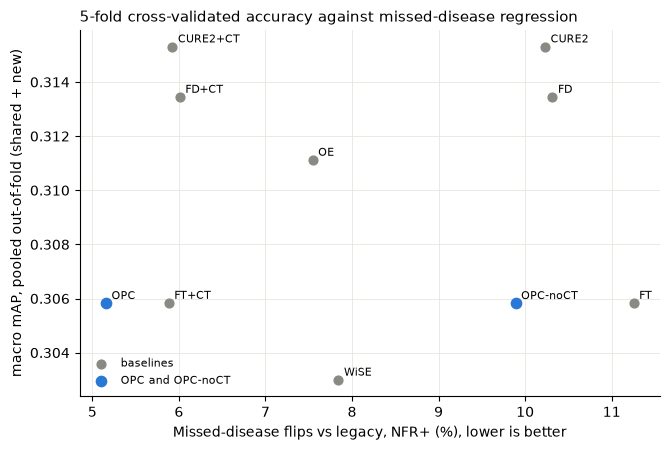

In [9]:
ORDER = ["Legacy", "Legacy-recal", "FT", "FT+CT", "FD", "FD+CT", "WiSE", "OE", "CURE2", "CURE2+CT", "OPC-noCT", "OPC"]
MP = CFG["min_pos"]

def pooled(method, seed):
    L = np.zeros((len(pool), len(UNION)), np.float32)
    T = np.zeros_like(L)
    v1 = []
    for k in range(K_FOLDS):
        z = np.load(run_file(method, seed, k))
        te = np.where(folds == k)[0]
        L[te], T[te] = z["L"], z["thr"][None, :]
        v1.append(float(z["v1"]))
    return L, T, float(np.mean(v1))

available = [m for m in ORDER if all(run_file(m, s, k).exists() for s in SEEDS for k in range(K_FOLDS))]
RUNS, rows = {}, []
for s in SEEDS:
    L_old = pooled("Legacy", s)[0]
    thr_old = np.load(run_file("Legacy", s, 0))["thr"]
    for m in available:
        L, T, v1 = pooled(m, s)
        RUNS[(m, s)] = (L, T)
        res = cv.pooled_metrics(L, T, L_old, thr_old, Yp, Mp, GROUPS, SH, MP)
        res.pop("per_class_ap")
        if m.startswith("Legacy"):
            for g in ("new", "all", "all_exHR", f"all_min{MP}"):
                res[f"mAP_{g}"] = np.nan
        rows.append(dict(res, method=m, seed=s, mAP_v1_retention=v1))
df = pd.DataFrame(rows)
KEYS = ["mAP_all", f"mAP_all_min{MP}", "mAP_shared", "mAP_new", "mAP_all_exHR", "NFR_%", "NFR+_%",
        "NFR+_scoreonly_%", "PFR_%", f"regressed_classes_min{MP}", "mAP_v1_retention"]
mean = df.groupby("method")[KEYS].mean().reindex(available)
sd = df.groupby("method")[KEYS].std().reindex(available)
fmt = lambda m, s: "nan" if pd.isna(m) else (f"{m:.4f}" if pd.isna(s) else f"{m:.4f} ± {s:.4f}")
table = pd.DataFrame({k: [fmt(m, s) for m, s in zip(mean[k], sd[k])] for k in KEYS}, index=mean.index)
table.to_csv(RES / ("cv_table_quick.csv" if QUICK else "cv_table.csv"))
display(table[["mAP_all", f"mAP_all_min{MP}", "NFR_%", "NFR+_%", "NFR+_scoreonly_%", f"regressed_classes_min{MP}", "mAP_v1_retention"]])

fig, ax = plt.subplots(figsize=(6.8, 4.6))
pts = [m for m in available if not m.startswith("Legacy")]
ours = [m for m in pts if m.startswith("OPC")]
ax.scatter(mean.loc[[m for m in pts if m not in ours], "NFR+_%"], mean.loc[[m for m in pts if m not in ours], "mAP_all"],
           s=40, color="#8a8a85", label="baselines", zorder=3)
ax.scatter(mean.loc[ours, "NFR+_%"], mean.loc[ours, "mAP_all"], s=55, color="#2a78d6", label="OPC and OPC-noCT", zorder=4)
for m in pts:
    ax.annotate(m, (mean.loc[m, "NFR+_%"], mean.loc[m, "mAP_all"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Missed-disease flips vs legacy, NFR+ (%), lower is better")
ax.set_ylabel("macro mAP, pooled out-of-fold (shared + new)")
ax.set_title("5-fold cross-validated accuracy against missed-disease regression", loc="left", fontsize=11)
ax.grid(color="#e6e5df", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(RES / ("cv_pareto_quick.png" if QUICK else "cv_pareto.png"), dpi=200)
plt.show()

## 8. Paired bootstrap


In [10]:
cols_boot = [c for c in SH + NW if npos[c] >= MP]
L_old0 = {s: pooled("Legacy", s)[0] for s in SEEDS}
thr_old0 = {s: np.load(run_file("Legacy", s, 0))["thr"] for s in SEEDS}

def boot(a, b):
    return cv.paired_bootstrap([RUNS[(a, s)] for s in SEEDS], [RUNS[(b, s)] for s in SEEDS], Yp, Mp, cols_boot, SH,
                               [L_old0[s] for s in SEEDS], [thr_old0[s] for s in SEEDS], n_boot=CFG["n_boot"], seed=0)

t0 = time.time()
CMP = {}
pairs = [("FT+CT", "FT"), ("OPC", "FT"), ("OPC", "FD"), ("OPC", "FD+CT"), ("OPC", "WiSE"), ("OPC", "OE"),
         ("OPC", "FT+CT"), ("OPC", "OPC-noCT")]
for a, b in pairs:
    if a in available and b in available:
        CMP[f"{a} - {b}"] = boot(a, b)
print(f"bootstrap done in {(time.time() - t0) / 60:.1f} min")
display(pd.DataFrame(CMP).T.rename(columns=lambda c: c + "  [mean, 2.5%, 97.5%]"))

m_ = lambda name, key: float(mean.loc[name, key]) if name in mean.index else float("nan")
G = {}
G["G1_FT_NFR+_ge_5"] = bool(m_("FT", "NFR+_%") >= 5.0)
G["G2_CT_reduces_flips"] = bool("FT+CT - FT" in CMP and CMP["FT+CT - FT"]["d_NFR+"][2] < 0)
rivals = [b for b in ("FD", "FD+CT", "WiSE", "OE", "FT+CT") if b in mean.index]
best_rival = min(rivals, key=lambda b: m_(b, "NFR+_%")) if rivals else None
G["best_NFR+_rival"] = best_rival
G["G3_OPC_wins"] = bool(best_rival is not None and f"OPC - {best_rival}" in CMP
                        and CMP[f"OPC - {best_rival}"]["d_NFR+"][2] < 0
                        and "OPC - FD" in CMP and CMP["OPC - FD"]["d_mAP"][0] >= -0.01)
c4 = CMP.get("OPC - FT+CT")
G["G4_training_part_matters"] = bool(c4 is not None and (c4["d_NFR+"][2] < 0 or c4["d_mAP"][1] > 0))
verdict = ("STOP" if not G["G1_FT_NFR+_ge_5"] else "GO" if G["G3_OPC_wins"]
           else "CT-ONLY" if G["G2_CT_reduces_flips"] else "REVISE")

send = {
    "notebook": "04_cv_opc", "quick_mode": QUICK, "seeds": SEEDS, "folds": K_FOLDS,
    "pooled_images": len(pool), "near_duplicate_groups": int(groups.max() + 1),
    "pooled_shared_positive_labels": int((Yp[:, SH] * Mp[:, SH]).sum()),
    f"classes_min{MP}": len(cols_boot),
    "means": mean.round(4).to_dict(orient="index"),
    "sd_mAP_all": sd["mAP_all"].round(4).to_dict(), "sd_NFR+": sd["NFR+_%"].round(3).to_dict(),
    "bootstrap": CMP, "gates": G, "verdict": verdict,
}
(RES / ("cv_summary_quick.json" if QUICK else "cv_summary.json")).write_text(json.dumps(send, indent=1, default=str))
print("=" * 30, "SEND THIS BACK", "=" * 30)
print(json.dumps(send, default=str))

bootstrap done in 7.8 min


,"d_mAP [mean, 2.5%, 97.5%]","d_NFR+ [mean, 2.5%, 97.5%]"
FT+CT - FT,"[0.0, 0.0, 0.0]","[-5.3708, -6.4047, -4.3809]"
OPC - FT,"[-0.0049, -0.0223, 0.0186]","[-6.0955, -7.3969, -4.9041]"
OPC - FD,"[-0.0089, -0.031, 0.0103]","[-5.1577, -6.3179, -4.0262]"
OPC - FD+CT,"[-0.0089, -0.031, 0.0103]","[-0.8525, -1.6804, 0.0]"
OPC - WiSE,"[0.0099, -0.0104, 0.0332]","[-2.6854, -3.9053, -1.4827]"
OPC - OE,"[-0.0018, -0.0203, 0.0211]","[-2.387, -3.4846, -1.1887]"
OPC - FT+CT,"[-0.0049, -0.0223, 0.0186]","[-0.7246, -1.5132, 0.0887]"
OPC - OPC-noCT,"[0.0, 0.0, 0.0]","[-4.7315, -5.9241, -3.6452]"


============================== SEND THIS BACK ==============================
{"notebook": "04_cv_opc", "quick_mode": false, "seeds": [0, 1, 2], "folds": 5, "pooled_images": 748, "near_duplicate_groups": 729, "pooled_shared_positive_labels": 782, "classes_min5": 32, "means": {"Legacy": {"mAP_all": NaN, "mAP_all_min5": NaN, "mAP_shared": 0.1827, "mAP_new": NaN, "mAP_all_exHR": NaN, "NFR_%": 0.0, "NFR+_%": 0.0, "NFR+_scoreonly_%": 0.0, "PFR_%": 0.0, "regressed_classes_min5": 0.0, "mAP_v1_retention": 0.3995}, "Legacy-recal": {"mAP_all": NaN, "mAP_all_min5": NaN, "mAP_shared": 0.1827, "mAP_new": NaN, "mAP_all_exHR": NaN, "NFR_%": 11.699, "NFR+_%": 6.2234, "NFR+_scoreonly_%": 0.0, "PFR_%": 3.9462, "regressed_classes_min5": 0.0, "mAP_v1_retention": 0.3995}, "FT": {"mAP_all": 0.3058, "mAP_all_min5": 0.3921, "mAP_shared": 0.3104, "mAP_new": 0.2902, "mAP_all_exHR": 0.2986, "NFR_%": 6.525, "NFR+_%": 11.2532, "NFR+_scoreonly_%": 8.0989, "PFR_%": 9.0979, "regressed_classes_min5": 2.3333, "mAP_v1_re